# 期望價值排序

**目的**：轉化傾向模型只回答「誰最可能轉化」，但商業目標是**手續費收入**。期望價值把「轉化後能帶來多少收入」納入排序，讓名單和商業目標一致（計畫書 4.4）。

```
每位轉化客戶的年手續費 = 月扣款 × 12 × 申購費率 + 月扣款 × 6.5 × 經理費率
期望價值 = 轉化機率 × 每位轉化客戶的年手續費
```

| 步驟 | 內容 |
| --- | --- |
| 1 | 依附錄 A 的規則計算月扣款，篩選可推薦客戶 |
| 2 | 計算年手續費與期望價值（基金／ETF 兩種情境） |
| 3 | 產生兩份名單：機率排序 vs 期望價值排序 |
| 4 | 比較兩份名單：重疊、被替換的客戶、期望手續費 |
| 5 | 評估成效：用「模型沒看過他」的分數，比較實際轉化者的預估手續費 |
| 6 | 輸出接觸名單，給內容過濾推薦使用 |

> 本專案使用模擬資料，以下所有結果都是**模擬資料中的規律**，在真實情境下是否成立需要驗證（見計畫書 1.5）。

## 0. 環境設定與讀取資料

In [ ]:
import os, subprocess
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.font_manager as fm

# 中文字型:Colab(Linux)沒有內建中文字型,找不到時自動安裝 Noto Sans CJK
CJK_FONT = "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"
if not any(f.name.startswith(("Microsoft JhengHei", "PingFang", "Heiti", "Noto Sans CJK")) for f in fm.fontManager.ttflist):
    if not os.path.exists(CJK_FONT):
        subprocess.run(["apt-get", "-qq", "install", "-y", "fonts-noto-cjk"], check=True)
    fm.fontManager.addfont(CJK_FONT)

plt.rcParams["font.sans-serif"] = ["Microsoft JhengHei", "PingFang TC", "Heiti TC", "Noto Sans CJK TC", "Noto Sans CJK JP", "Arial Unicode MS"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110

MAIN = "#2a78d6"     # 期望價值排序
REF = "#52514e"      # 機率排序、參考線
MUTED = "#a8a7a2"    # 隨機、次要資訊
pd.set_option("display.max_columns", None)

# 假設參數(附錄 A),集中在這裡定義
EMERGENCY_MONTHS = 3            # 緊急預備金 = 3 個月的刷卡支出
MIN_SIP, MAX_SIP = 1_000, 10_000  # 最低扣款門檻、月扣款上限
MIN_INVESTABLE = 12 * MIN_SIP     # 推薦門檻:一年至少要能扣 12,000 元
AVG_ASSET_MONTHS = 6.5          # 年平均累積資產 = 月扣款 × 6.5
TOP_SHARE = 0.2                 # 接觸可推薦客戶的前 20%
RATES = {"基金": {"申購": 0.015, "經理": 0.015},
         "ETF": {"申購": 0.001, "經理": 0.004}}

In [ ]:
def path(name, folder):
    """Colab 直接上傳時檔案在根目錄;下載整個 repo 執行時在資料夾裡"""
    return name if os.path.exists(name) else os.path.join(folder, name)

scores = pd.read_csv(path("propensity_scores.csv", "outputs"))     # 轉化傾向模型第 9 節的輸出
deposit_balance = pd.read_csv(path("deposit_balance_cleaned.csv", "data_cleaned"), parse_dates=["month"])
card_transactions = pd.read_csv(path("card_transactions_cleaned.csv", "data_cleaned"), parse_dates=["transaction_month"])

assert scores["customer_id"].is_unique and len(scores) == 7717
assert {"p_convert", "p_convert_oof", "y"} <= set(scores.columns)
print("分析母體:", len(scores), "人")
print("活存期間:", deposit_balance["month"].min().date(), "~", deposit_balance["month"].max().date())
print("刷卡期間:", card_transactions["transaction_month"].min().date(), "~", card_transactions["transaction_month"].max().date())

分析母體: 7717 人
活存期間: 2025-08-01 ~ 2026-07-01
刷卡期間: 2026-03-01 ~ 2026-08-01


## 1. 計算月扣款，篩選可推薦客戶

資料中沒有扣款金額，依附錄 A 的規則由閒置資金推估：

| 步驟 | 定義 |
| --- | --- |
| 平均活存 | 2025/08–2026/07 每月餘額的平均（與模型特徵 `avg_balance_12m` 相同） |
| 每月刷卡 | 2026/03–2026/08 刷卡總額 ÷ 6 |
| 可投資閒置資金 | 平均活存 − 3 × 每月刷卡（先保留 3 個月生活費當緊急預備金） |
| 月扣款 | 可投資閒置資金 ÷ 12（用一年分批投入），**無條件捨去**到千元，上限 10,000 元 |
| 可推薦客戶 | 可投資閒置資金 **≥ 12,000 元**（一年至少能扣最低門檻 1,000 元 × 12 個月） |

**為什麼這樣定**：一年的扣款不能超過可投資閒置資金，否則會動用緊急預備金，違反「先保留緊急預備金」的前提。原本的規則是「可投資閒置資金 > 0 就推薦、1–999 元拉到 1,000、四捨五入到千元」，檢查後發現可推薦客戶中有 53.1% 一年的扣款會超過可投資閒置資金（被拉到下限的 1,229 人全部超過，四捨五入進位的 1,949 人也會超過），因此修正為目前的規則。閒置資金未滿 12,000 元的客戶不是沒有價值，而是不適合這個商品的扣款門檻（見計畫書第 6 節「下一步」）。

In [ ]:
assert deposit_balance.groupby("customer_id")["month"].nunique().eq(12).all()
assert card_transactions["transaction_month"].nunique() == 6
avg_balance = deposit_balance.groupby("customer_id")["checking_balance"].mean()
monthly_spend = card_transactions.groupby("customer_id")["transaction_amount"].sum() / 6

df = scores.copy()
df["avg_balance_12m"] = df["customer_id"].map(avg_balance)
df["monthly_spend_6m"] = df["customer_id"].map(monthly_spend)
assert df[["avg_balance_12m", "monthly_spend_6m"]].notna().all().all()

df["investable"] = df["avg_balance_12m"] - EMERGENCY_MONTHS * df["monthly_spend_6m"]
df["sip_raw"] = df["investable"] / 12
df["eligible"] = df["investable"] >= MIN_INVESTABLE
# 無條件捨去到千元、上限 10,000:一年的扣款不會超過可投資閒置資金
df["sip"] = (df["sip_raw"].clip(upper=MAX_SIP) // 1000) * 1000

elig = df[df["eligible"]].copy().reset_index(drop=True)
assert len(elig) == 4755
assert (elig["sip"] >= MIN_SIP).all()
assert (elig["sip"] * 12 <= elig["investable"]).all()     # 不會動用緊急預備金
N_TOP = round(len(elig) * TOP_SHARE)

no_idle = df["investable"] <= 0
too_small = (df["investable"] > 0) & ~df["eligible"]
print(f"可推薦客戶: {len(elig):,} 人({len(elig) / len(df):.1%}),前 20% = {N_TOP:,} 人")
print(f"不推薦:沒有閒置資金 {no_idle.sum():,} 人、閒置資金未滿 {MIN_INVESTABLE:,} 元 {too_small.sum():,} 人")
print(f"可推薦客戶中,月扣款計算值 ≥ 10,000(截在上限): {(elig['sip_raw'] >= MAX_SIP).mean():.1%}")
print(f"轉化率:可推薦客戶 {elig['y'].mean():.1%} vs 閒置資金未滿 12,000 元 {df.loc[too_small, 'y'].mean():.1%}"
      f" vs 沒有閒置資金 {df.loc[no_idle, 'y'].mean():.1%}")

可推薦客戶: 4,755 人(61.6%),前 20% = 951 人
不推薦:沒有閒置資金 1,733 人、閒置資金未滿 12,000 元 1,229 人
可推薦客戶中,月扣款計算值 ≥ 10,000(截在上限): 10.5%
轉化率:可推薦客戶 8.2% vs 閒置資金未滿 12,000 元 5.4% vs 沒有閒置資金 3.8%


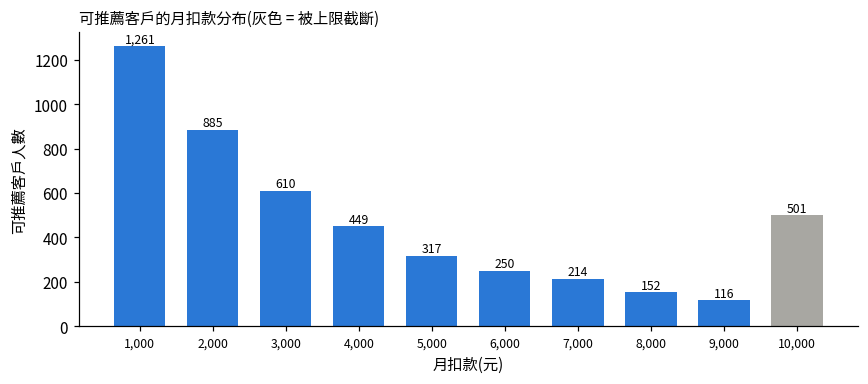

In [ ]:
counts = elig["sip"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 3.6))
colors = [MUTED if v == MAX_SIP else MAIN for v in counts.index]
ax.bar(counts.index / 1000, counts.values, color=colors, width=0.7)
for x, n in zip(counts.index / 1000, counts.values):
    ax.text(x, n + 15, f"{n:,}", ha="center", fontsize=8)
ax.set_xticks(counts.index / 1000, [f"{v:,.0f}" for v in counts.index], fontsize=8)
ax.set_xlabel("月扣款(元)")
ax.set_ylabel("可推薦客戶人數")
ax.set_title("可推薦客戶的月扣款分布(灰色 = 被上限截斷)", loc="left", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**我的解讀**：
可推薦客戶佔母體的61.6%，月扣款分布呈現右偏，
只有最右端因為上限設置在10,000，所以都堆積在尾端

沒有閒置資金的1,733人跟閒置資金未滿12,000元的1,229人被排除
被上限截斷的客戶在期望價值排序中，作為月扣款最高的一群人，
因為月扣款都相同，所以會以機率高低進行排序

轉化率會隨閒置資金遞減，可推薦客戶 8.2%、閒置資金未滿 12,000 元 5.4%、沒有閒置資金 3.8%。

## 2. 年手續費與期望價值

```
每位轉化客戶的年手續費 = 月扣款 × (12 × 申購費率 + 6.5 × 經理費率)
```

括號裡的數字對每位客戶都一樣，稱為**手續費係數**。

| 情境 | 申購費率 | 經理費率 | 手續費係數 |
| --- | --- | --- | --- |
| 基金 | 1.5% | 1.5% | 12 × 1.5% + 6.5 × 1.5% = 0.2775 |
| ETF | 0.1% | 0.4% | 12 × 0.1% + 6.5 × 0.4% = 0.038 |

- **費率不影響排序**：期望價值 = 轉化機率 × 月扣款 × 手續費係數。係數對每位客戶都一樣，所以兩種情境的名單完全相同，只有金額不同。推薦結果出來前不知道客戶會買基金還是 ETF，所以收入以兩種情境的**區間**呈現。
- **只算轉化後第一年**、**不考慮投資報酬**、**不扣接觸成本**（見計畫書 4.4、附錄 A）。金額是**預估手續費收入**（毛收入），不是淨收益。
- **關鍵假設**：標籤代表**沒有行銷介入**的自然轉化，所以期望價值是「這位客戶本來就可能帶來的收入」，不是「接觸他能多賺的收入」。期望價值排序成立的前提是：**行銷對每位客戶的相對提升相同**。若提升因人而異（例如高傾向客戶本來就會轉化），需要用 A/B 測試（計畫書 1.5）或 uplift 模型修正。

In [ ]:
SCENARIO = {"基金": "fund", "ETF": "etf"}
fee_factor = {name: 12 * r["申購"] + AVG_ASSET_MONTHS * r["經理"] for name, r in RATES.items()}
for name, key in SCENARIO.items():
    elig[f"fee_{key}"] = elig["sip"] * fee_factor[name]          # 每位轉化客戶的年手續費
    elig[f"ev_{key}"] = elig["p_convert"] * elig[f"fee_{key}"]    # 期望價值

print("手續費係數:", {k: round(v, 4) for k, v in fee_factor.items()})
print(f"範例:月扣款 5,000 元 → 基金 {5000 * fee_factor['基金']:,.1f} 元、ETF {5000 * fee_factor['ETF']:,.1f} 元")

# 費率不影響排序:兩種情境的期望價值完全成正比
print("兩種情境的期望價值相關係數(Spearman):",
      round(elig[["ev_fund", "ev_etf"]].corr(method="spearman").iloc[0, 1], 6))

手續費係數: {'基金': 0.2775, 'ETF': 0.038}
範例:月扣款 5,000 元 → 基金 1,387.5 元、ETF 190.0 元
兩種情境的期望價值相關係數(Spearman): 1.0


## 3. 產生兩份名單

- **機率排序**：依轉化機率 `p_convert`。
- **期望價值排序**：依 `p_convert × 月扣款`（手續費係數對每個人都一樣，排序時可以省略）。
- 兩份名單都**先篩選可推薦客戶，再取前 20%（951 人）**，確保兩份名單的差異只來自排序方式。
- 這一節用 `p_convert`（第 4 節訓練好的模型）產生名單；評估成效放在第 5 節，改用「模型沒看過他」的分數。

In [ ]:
def top_ids(data, score):
    """依 score 由高到低取前 N_TOP 位客戶的 customer_id"""
    rank = data[score].rank(ascending=False, method="first")
    return set(data.loc[rank <= N_TOP, "customer_id"])

elig["ev_score"] = elig["p_convert"] * elig["sip"]
list_prob = top_ids(elig, "p_convert")
list_ev = top_ids(elig, "ev_score")
assert len(list_prob) == len(list_ev) == N_TOP
print(f"機率排序名單 {len(list_prob):,} 人,期望價值排序名單 {len(list_ev):,} 人")

機率排序名單 951 人,期望價值排序名單 951 人


## 4. 比較兩份名單

- **重疊**：兩份名單有多少人相同。
- **被替換的客戶**：只在其中一份名單的人，他們的機率和月扣款有什麼不同。
- **期望手續費**：名單中每位客戶的期望價值加總。⚠️ 這是期望價值排序**自己的目標**，它在這個指標上一定贏，所以只能當參考；公平的比較在第 5 節。

In [ ]:
both, only_prob, only_ev = list_prob & list_ev, list_prob - list_ev, list_ev - list_prob
print(f"重疊 {len(both):,} 人({len(both) / N_TOP:.1%}),各有 {len(only_prob):,} 人被替換")

def describe(ids):
    g = elig[elig["customer_id"].isin(ids)]
    return {"人數": len(g), "機率中位數": g["p_convert"].median(), "月扣款中位數": g["sip"].median()}

swap = pd.DataFrame({"兩份名單都有": describe(both),
                     "只在機率名單": describe(only_prob),
                     "只在期望價值名單": describe(only_ev)}).T
swap.style.format({"人數": "{:,.0f}", "機率中位數": "{:.3f}", "月扣款中位數": "{:,.0f}"})

重疊 703 人(73.9%),各有 248 人被替換


,人數,機率中位數,月扣款中位數
兩份名單都有,703,0.178,"10,000"
只在機率名單,248,0.141,"3,000"
只在期望價值名單,248,0.102,"10,000"


In [ ]:
def list_summary(ids):
    g = elig[elig["customer_id"].isin(ids)]
    return {"機率中位數": g["p_convert"].median(),
            "月扣款中位數": g["sip"].median(),
            "期望手續費(基金)": g["ev_fund"].sum(),
            "期望手續費(ETF)": g["ev_etf"].sum(),
            "月扣款 = 10,000 的人數": (g["sip"] == MAX_SIP).sum(),
            "月扣款 = 1,000 的人數": (g["sip"] == MIN_SIP).sum()}

compare_lists = pd.DataFrame({"機率排序": list_summary(list_prob), "期望價值排序": list_summary(list_ev)})
(compare_lists.style.format("{:,.0f}")
 .format("{:.3f}", subset=pd.IndexSlice[["機率中位數"], :]))

,機率排序,期望價值排序
機率中位數,0.164,0.157
月扣款中位數,"8,000","10,000"
期望手續費(基金),"354,566","389,392"
期望手續費(ETF),"48,553","53,322"
"月扣款 = 10,000 的人數",353,479
"月扣款 = 1,000 的人數",51,0


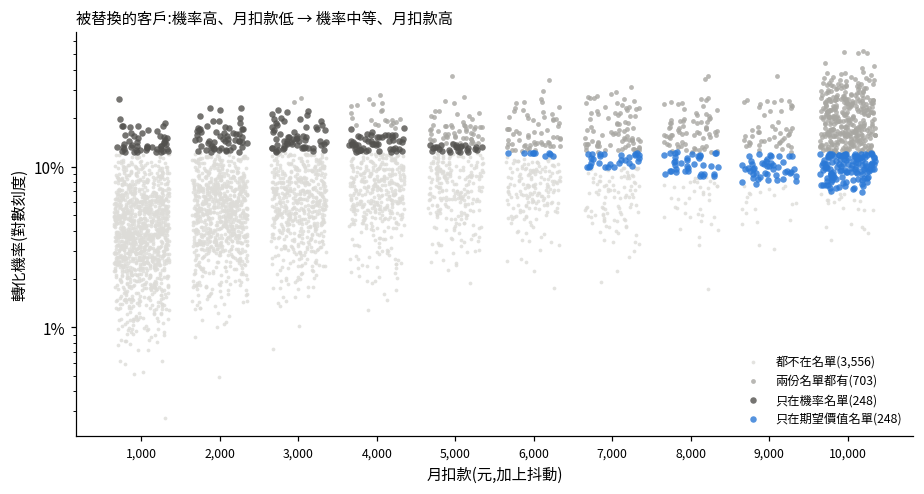

In [ ]:
group = np.select([elig["customer_id"].isin(both), elig["customer_id"].isin(only_prob), elig["customer_id"].isin(only_ev)],
                  ["兩份名單都有", "只在機率名單", "只在期望價值名單"], "都不在名單")
rng = np.random.default_rng(42)
jitter = rng.uniform(-350, 350, len(elig))        # 月扣款是千元整數,加一點抖動避免點重疊

fig, ax = plt.subplots(figsize=(8.5, 4.6))
style = {"都不在名單": ("#dddcd8", 6), "兩份名單都有": (MUTED, 10),
         "只在機率名單": (REF, 18), "只在期望價值名單": (MAIN, 18)}
for name, (color, size) in style.items():
    m = group == name
    ax.scatter(elig.loc[m, "sip"] + jitter[m], elig.loc[m, "p_convert"], s=size, color=color,
               alpha=0.8, linewidths=0, label=f"{name}({m.sum():,})")
ax.set_yscale("log")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_xticks(range(1000, 10001, 1000), [f"{v:,}" for v in range(1000, 10001, 1000)], fontsize=8)
ax.set_xlabel("月扣款(元,加上抖動)")
ax.set_ylabel("轉化機率(對數刻度)")
ax.set_title("被替換的客戶:機率高、月扣款低 → 機率中等、月扣款高", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**我的解讀**：
重疊703人(73.9%)，只在機率名單跟只在期望價值名單的比較，
機率中位數:0.141 vs 0.102，月扣款中位數:3,000 vs 10,000

只在機率排序出現的人，機率高、月扣款較低。
只在期望價值排序出現的人，機率中，月扣款高

月扣款1,000的人只出現在機率名單當中(51 vs 0人)
大多數被上限截斷的人，都在期望價值名單中(機率名單 353 人 vs 期望價值名單 479 人)

為什麼「期望手續費」只能當參考:
因為這裡是把名單內每位客戶的期望價值加總，這是期望價值排序的目標，所以一定會表現得比機率排序較好

## 5. 評估成效：實際轉化者的預估手續費

**為什麼要換分數**：`p_convert` 中 70% 的客戶是訓練集，他們的分數是「模型看過答案」的分數，用來評估會偏樂觀。這裡改用轉化傾向模型第 9 節的 `p_convert_oof`：5-fold 交叉驗證中，每位客戶的分數都來自**沒看過他**的模型，所以可以在全部 4,755 位可推薦客戶上評估。

**指標**：

| 指標 | 意思 |
| --- | --- |
| 實際轉化人數 | 名單中真的轉化的人數 |
| 名單轉化率 | 實際轉化人數 ÷ 名單人數（附 95% 信賴區間） |
| 抓到的轉化者比例 | 實際轉化人數 ÷ 可推薦客戶中全部的轉化者 |
| **實際轉化者的預估手續費** | 名單中**實際轉化**的客戶，用月扣款規則**推估**的年手續費加總。轉化結果是實際的，手續費是推估的（資料沒有扣款紀錄），所以不叫「實際收入」 |

**比較基準**：隨機挑 20% 的客戶，期望能抓到 20% 的轉化者和 20% 的預估手續費。

In [ ]:
elig["ev_score_oof"] = elig["p_convert_oof"] * elig["sip"]
eval_lists = {"機率排序": top_ids(elig, "p_convert_oof"), "期望價值排序": top_ids(elig, "ev_score_oof")}

total_conv = elig["y"].sum()
total_fee = {key: (elig["y"] * elig[f"fee_{key}"]).sum() for key in SCENARIO.values()}

def evaluate(ids):
    g = elig[elig["customer_id"].isin(ids)]
    conv = g["y"].sum()
    rate = conv / len(g)
    return {"實際轉化人數": conv,
            "名單轉化率": rate,
            "誤差": 1.96 * np.sqrt(rate * (1 - rate) / len(g)),
            "抓到的轉化者比例": conv / total_conv,
            "實際轉化者的預估手續費(基金)": (g["y"] * g["fee_fund"]).sum(),
            "實際轉化者的預估手續費(ETF)": (g["y"] * g["fee_etf"]).sum(),
            "抓到的預估手續費比例": (g["y"] * g["fee_fund"]).sum() / total_fee["fund"]}

base = elig["y"].mean()
random_row = {"實際轉化人數": N_TOP * base, "名單轉化率": base, "誤差": np.nan,
              "抓到的轉化者比例": TOP_SHARE,
              "實際轉化者的預估手續費(基金)": TOP_SHARE * total_fee["fund"],
              "實際轉化者的預估手續費(ETF)": TOP_SHARE * total_fee["etf"],
              "抓到的預估手續費比例": TOP_SHARE}
result = pd.DataFrame({"隨機(期望值)": random_row, **{k: evaluate(v) for k, v in eval_lists.items()}}).T

print(f"可推薦客戶中共有 {total_conv} 位轉化者,他們的預估手續費:基金 {total_fee['fund']:,.0f} 元、ETF {total_fee['etf']:,.0f} 元")
diff = result.loc["期望價值排序"] - result.loc["機率排序"]
print(f"期望價值排序 vs 機率排序:轉化者 {diff['實際轉化人數']:+.0f} 人,"
      f"預估手續費(基金){diff['實際轉化者的預估手續費(基金)']:+,.0f} 元"
      f"({diff['實際轉化者的預估手續費(基金)'] / result.loc['機率排序', '實際轉化者的預估手續費(基金)']:+.1%})")
result.style.format({"實際轉化人數": "{:,.0f}", "名單轉化率": "{:.1%}", "誤差": "±{:.1%}", "抓到的轉化者比例": "{:.1%}",
                     "實際轉化者的預估手續費(基金)": "{:,.0f}", "實際轉化者的預估手續費(ETF)": "{:,.0f}",
                     "抓到的預估手續費比例": "{:.1%}"}, na_rep="—")

可推薦客戶中共有 388 位轉化者,他們的預估手續費:基金 604,395 元、ETF 82,764 元
期望價值排序 vs 機率排序:轉化者 +0 人,預估手續費(基金)+40,237 元(+10.1%)


,實際轉化人數,名單轉化率,誤差,抓到的轉化者比例,實際轉化者的預估手續費(基金),實際轉化者的預估手續費(ETF),抓到的預估手續費比例
隨機(期望值),78,8.2%,—,20.0%,"120,879","16,553",20.0%
機率排序,183,19.2%,±2.5%,47.2%,"398,490","54,568",65.9%
期望價值排序,183,19.2%,±2.5%,47.2%,"438,727","60,078",72.6%


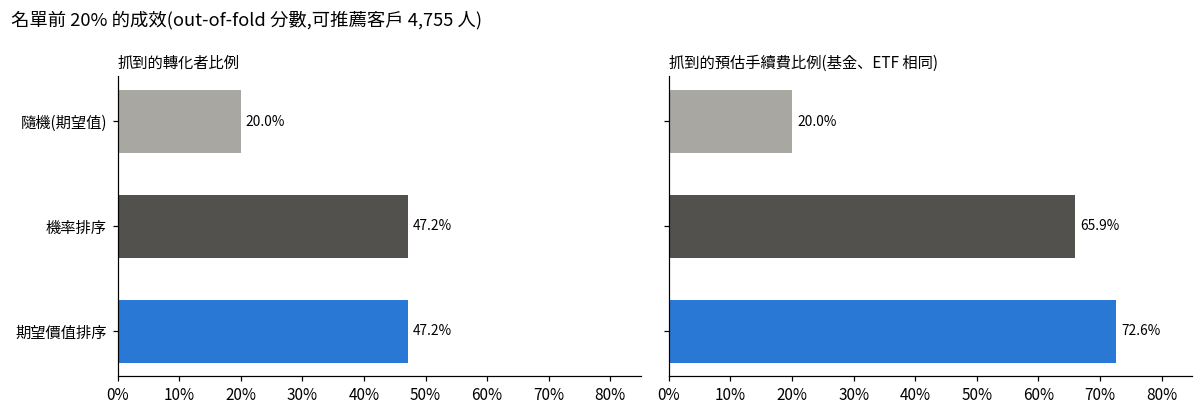

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
labels = result.index.tolist()
colors = [MUTED, REF, MAIN]
for ax, col, title in [(axes[0], "抓到的轉化者比例", "抓到的轉化者比例"),
                       (axes[1], "抓到的預估手續費比例", "抓到的預估手續費比例(基金、ETF 相同)")]:
    ax.barh(labels, result[col], color=colors, height=0.6)
    for i, v in enumerate(result[col]):
        ax.text(v + 0.008, i, f"{v:.1%}", va="center", fontsize=9)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
    ax.set_xlim(0, 0.85)
    ax.set_title(title, loc="left", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].invert_yaxis()
fig.suptitle(f"名單前 20% 的成效(out-of-fold 分數,可推薦客戶 {len(elig):,} 人)", x=0.01, ha="left")
plt.tight_layout()
plt.show()

**我的解讀**：

期望價值名單抓出來的轉化者跟機率名單一樣多，
預估手續費(基金)多40,237元(10.1%)

如果使用期望價值排序，轉化者數量與機率排序相同，預估手續費會比較高。和預期一致

沒有做統計檢定，樣本小（183 位轉化者），所以無法排除雜訊。

取捨:
機率排序完全沒有用到月扣款，期望價值排序則是乘上月扣款，
如果月扣款錯估時，只有期望價值排序會受影響



關鍵假設:
標籤代表沒有行銷介入的自然轉化，所以期望價值是「這位客戶本來就可能帶來的收入」，不是「接觸他能多賺的收入」。期望價值排序成立的前提是「行銷對每位客戶的相對提升相同」
10.1%是自然轉化下的收入差距，不一定是行銷帶來的，
如果閒置資金多的客戶本來就會轉化，提升就不一樣，期望價值排序可能把資源浪費在不需要推薦的人身上。
後續用A/B 測試（接觸組 vs 保留組）來知道行銷真正多帶來多少價值（見計畫書 1.5）



## 6. 輸出接觸名單

- 依期望價值排序，輸出全部 4,755 位可推薦客戶，`in_top20 = True` 的 951 人就是接觸名單。
- 輸出 `outputs/contact_list.csv`，下一階段**內容過濾推薦與首次配置建議**（計畫書 4.5）使用；推薦時的建議月扣款就是這裡的 `sip`。

In [ ]:
contact = elig[["customer_id", "p_convert", "sip", "ev_fund", "ev_etf"]].copy()
contact["ev_rank"] = elig["ev_score"].rank(ascending=False, method="first").astype(int)
contact["in_top20"] = contact["customer_id"].isin(list_ev)
assert contact["in_top20"].sum() == N_TOP and (contact.loc[contact["in_top20"], "ev_rank"] <= N_TOP).all()

contact = contact.sort_values("ev_rank")
os.makedirs("outputs", exist_ok=True)
contact.to_csv("outputs/contact_list.csv", index=False)
print("已輸出:", len(contact), "位可推薦客戶,其中接觸名單", contact["in_top20"].sum(), "人")
contact.head()

已輸出: 4755 位可推薦客戶,其中接觸名單 951 人


,customer_id,p_convert,sip,ev_fund,ev_etf,ev_rank,in_top20
0,C108134,0.526789,10000.0,1461.840364,200.179942,1,True
1,C103236,0.514856,10000.0,1428.724742,195.645190,2,True
2,C104381,0.510169,10000.0,1415.718809,193.864197,3,True
3,C100492,0.510132,10000.0,1415.616534,193.850192,4,True
4,C101685,0.440311,10000.0,1221.863042,167.318182,5,True


## 總結

| 項目 | 結果 |
| --- | --- |
| 名單範圍與人數 | 可推薦客戶:4,755 人佔母體的61.6%，前 20% = 951 人。兩份名單都先篩選可推薦客戶，再取前 20%（951 人），確保兩份名單的差異只來自排序方式 |
| 月扣款 | 月扣款分布呈現右偏， 只有最右端因為上限設置在10,000，所以都堆積在尾端（10.5%）。沒有閒置資金的1,733人跟閒置資金未滿12,000元的1,229人被排除 |
| 兩份名單的差異 | 重疊703人(73.9%)，被替換的人從機率高、月扣款 3,000，替換成機率中等、月扣款 10,000|
| 評估結果 | 期望價值名單抓出來的轉化者跟機率名單一樣多(183 人)，預估手續費會比較高(10.1%)，和預期一致。沒有做統計檢定，樣本小（183 位轉化者），所以無法排除雜訊。 |
| 是否採用期望價值排序 | 採用期望價值排序，目標是手續費收入，與商業問題的目標有一致性、轉化人數與機率排序相同(183人)，預估手續費較高(OOF 評估，+10.1%)。風險是如果月扣款錯估，結果較容易受影響。但最壞的情況下，由於兩份名單有 73.9% 重疊，受影響的只限於被替換的 248 人。限制是手續費 +10.1%沒有做統計檢定，樣本小，無法排除雜訊。且兩種排序方式都無法去衡量行銷成效，所以後續要用A/B 測試驗證（見計畫書 1.5） |
| 限制 | ①標籤是自然轉化，期望價值不等於「接觸他能多賺的收入」。後續用A/B 測試（接觸組 vs 保留組）來知道行銷真正多帶來多少價值（見計畫書 1.5）。②月扣款是推估的，推估不準時期望價值排序會受影響。③費率為假設值（設定方式見計畫書附錄 A），預估手續費的金額只能看量級，但不影響排序。④只算第一年，低估長期價值，也假設客戶一年內都持續扣款。⑤閒置資金重複使用，平均餘額同時是模型特徵，也是月扣款的計算依據，排序會偏向資金多的客戶 |
| 下一步 | 內容過濾推薦與首次配置建議：依 KYC 過濾商品、依消費輪廓排序主題、組成核心＋衛星配置 |